# 1. EXPLORE DATA

**import libraries**

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split


**how many classes are there**

In [14]:
base_dir = Path('../data')

train_dir = base_dir / 'seg_train_test/seg_train'

train_classes = [x for x in train_dir.iterdir() if x.is_dir()]

print(train_classes)


[PosixPath('../data/seg_train_test/seg_train/street'), PosixPath('../data/seg_train_test/seg_train/glacier'), PosixPath('../data/seg_train_test/seg_train/forest'), PosixPath('../data/seg_train_test/seg_train/sea'), PosixPath('../data/seg_train_test/seg_train/buildings'), PosixPath('../data/seg_train_test/seg_train/mountain')]


**how many images per class**

In [26]:
imgs_count = {x.name : len(list(x.glob("*.jpg"))) for x in train_classes}
print(imgs_count)

{'street': 2883, 'glacier': 2957, 'forest': 2745, 'sea': 2784, 'buildings': 2628, 'mountain': 3037}


**some examples**

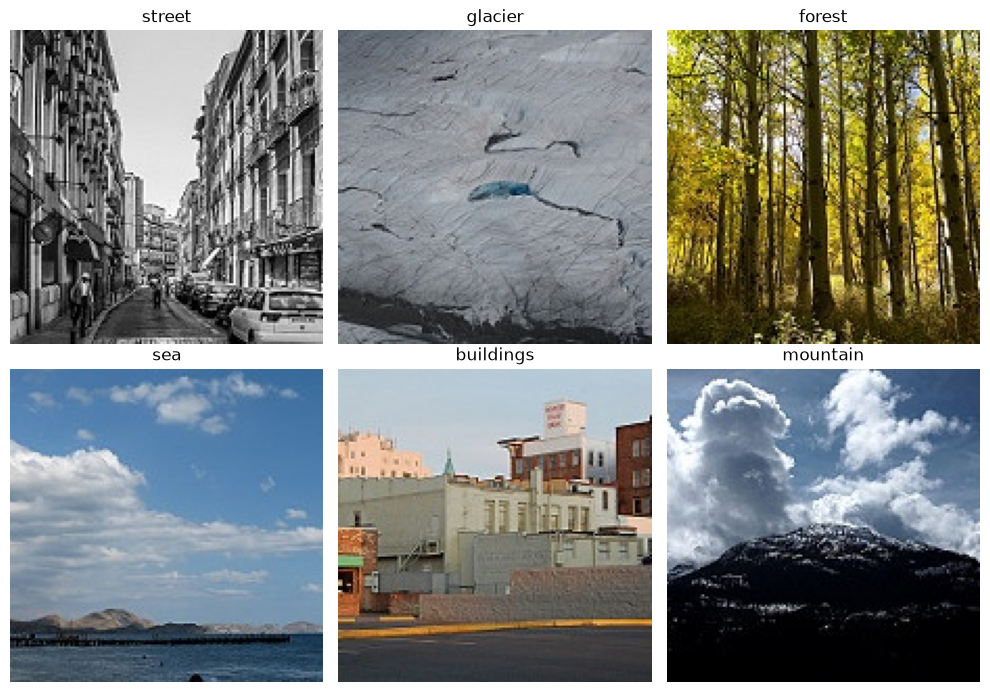

In [27]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(10, 7))
axes = axes.flatten()

for i, class_dir in enumerate(train_classes):
    # Grab the first image found in this class folder
    img_path = next(class_dir.glob("*.jpg"))
    img = Image.open(img_path)
    
    # Display the image and class name in slot i
    axes[i].imshow(img)
    axes[i].set_title(class_dir.name)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

**verify dimensions**

In [ ]:

path_list = list(train_dir.rglob("*.jpg"))

collection_size = {Image.open(x).size for x in path_list}

collection_format = {Image.open(x).format for x in path_list}

collection_mode = {Image.open(x).mode for x in path_list}


print(collection_size)
print(collection_format)
print(collection_mode)

{(150, 136), (150, 81), (150, 145), (150, 142), (150, 105), (150, 102), (150, 108), (150, 111), (150, 120), (150, 123), (150, 135), (150, 141), (150, 144), (150, 150), (150, 147), (150, 110), (150, 113), (150, 119), (150, 131), (150, 76), (150, 134), (150, 140), (150, 143), (150, 146), (150, 149), (150, 100), (150, 97), (150, 103), (150, 115), (150, 124), (150, 133), (150, 72)}
{'JPEG'}
{'RGB'}
[PosixPath('../data/seg_train_test/seg_train/street/8974.jpg'), PosixPath('../data/seg_train_test/seg_train/street/5974.jpg'), PosixPath('../data/seg_train_test/seg_train/street/18678.jpg'), PosixPath('../data/seg_train_test/seg_train/street/6558.jpg'), PosixPath('../data/seg_train_test/seg_train/street/19184.jpg'), PosixPath('../data/seg_train_test/seg_train/street/17713.jpg'), PosixPath('../data/seg_train_test/seg_train/street/7343.jpg'), PosixPath('../data/seg_train_test/seg_train/street/20819.jpg'), PosixPath('../data/seg_train_test/seg_train/street/1297.jpg'), PosixPath('../data/seg_train_t

**check corrupted files**

In [ ]:
corrupted = []

for i in path_list:
    try:
        verify = Image.open(i).verify()
    except:
        corrupted.append(i)


print(corrupted)

[]


## SPLITING DATA (TRAIN , VALIDATION , TEST)

In [52]:
x = path_list
y = [x.parent.name for x in path_list]

print(y)

['street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street', 'street',

**training with that data**

In [57]:
X_train , X_temp , y_train, y_temp = train_test_split(x, y , test_size=0.3 , random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42 , stratify=y_temp)